# UC Main Building: Indoor Navigation (Comp Graph)

**Scenario.** A visitor arrives at the lift lobby of the Universitas Ciputra Main Building on **Lt. 2**
and has to meet the Rector in **Ruang Rector (212C)**, which is on **Lt. 2A**, the half floor above.
The visitor walks with **W / A / S / D** (1 m per key press) and takes the open stair by the void to change level.

**Units.** Everything is in **meters**. 1 coordinate unit = 1 m. The origin (0, 0) is the south end of the stem, at the west wall
of the top bar. x grows east, y grows north. These are local coordinates, not longitude / latitude.
Room sizes were measured from the floor plan pictures, so they are **estimates (about +/- 0.5 m)**.

**Scope.** Lt. 2 and Lt. 2A are mapped. The other floors are added by the team as extra files and show up here without changing this notebook.

| Layer | Geometry | Content |
|---|---|---|
| Rooms | Polygon | one rectangle per room (from `csv/`) |
| User | Point | where the visitor stands |
| Trail / route | LineString | the path walked |

| GIS operation | What it does here (run on **every** step) |
|---|---|
| Buffer | circle of radius r around the user (Point to Polygon) |
| Spatial Join | rooms that intersect the buffer; rooms that intersect the trail |

In [1]:
import matplotlib.pyplot as plt
from shapely.geometry import LineString

from gis_ops import buffer_around, rooms_along_route, spatial_join
from map_view import add_polygon, draw_floor
from movement import Navigator

nav = Navigator("2")
print("Floors loaded:", list(nav.floors))
for name, data in nav.floors.items():
    print(f"  Lt. {name}: {len(data['rooms'])} rooms (Polygon layer), {len(data['walkable'])} corridor / lobby areas")

Floors loaded: ['2', '2A']
  Lt. 2: 39 rooms (Polygon layer), 14 corridor / lobby areas
  Lt. 2A: 34 rooms (Polygon layer), 24 corridor / lobby areas


## 1. The map (Polygon layer)
Sizes are in meters. Orange = lifts, red hatched = stairs, grey cross-hatch = the void (nobody can stand there).

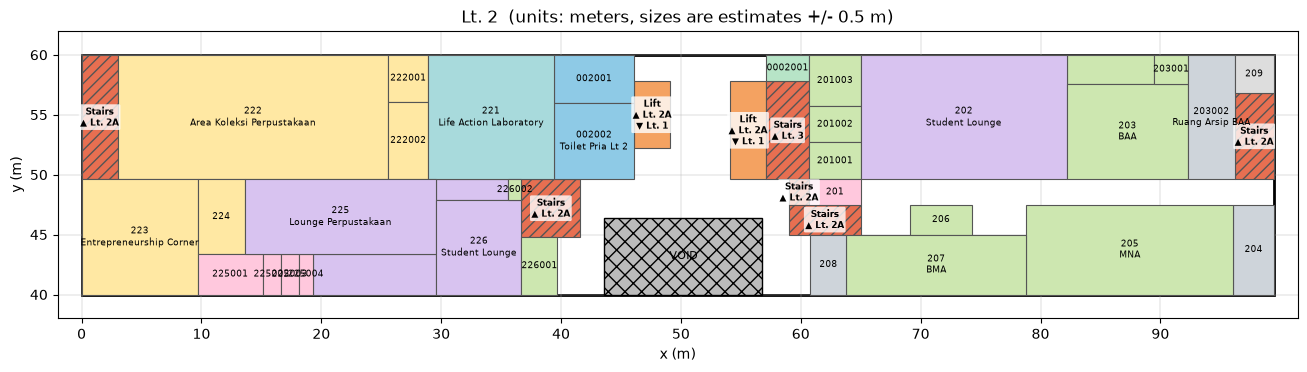

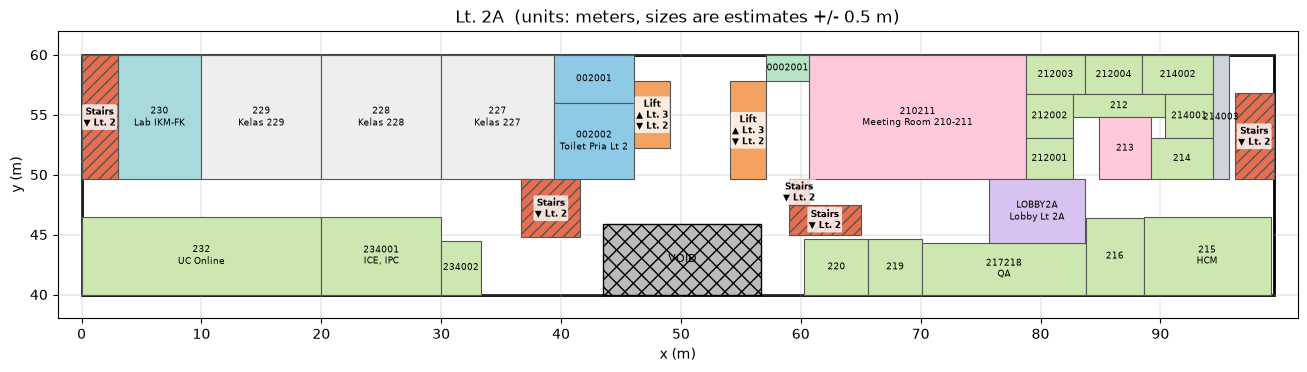

In [2]:
for floor in nav.floors:
    fig, ax = plt.subplots(figsize=(16, 4.8))
    data = nav.floors[floor]
    draw_floor(ax, floor, data["rooms"], data["walkable"])
    ax.set_title(f"Lt. {floor}  (units: meters, sizes are estimates +/- 0.5 m)")
    plt.show()

## 2. Walking with WASD, with Buffer and Spatial Join on every step
The walk below is scripted so the results are the same every time: 10 steps west (`A`), 8 steps south (`S`),
`E` to take the stair up to Lt. 2A, 40 steps east (`D`), 11 steps north (`W`).
Each step redraws nothing by hand: it moves the **Point**, makes the **Buffer**, and runs the **Spatial Join**
for the rooms in the buffer and the rooms the trail passed.

In [3]:
RADIUS = 5   # buffer radius in meters
nav = Navigator("2", radius=RADIUS)
log = []     # one row per step: (floor, x, y, room you are in, rooms in buffer, trail rooms)

def record(note=""):
    here = nav.here()
    log.append({"floor": nav.floor, "x": nav.x, "y": nav.y,
                "in": here["name"] if here else "corridor / lobby",
                "buffer": [r["room_id"] for r, _ in nav.nearby()],      # Buffer + Spatial Join
                "trail": [r["room_id"] for r in nav.visited()],         # LineString + Spatial Join
                "note": note})

def press(keys):
    for key in keys:
        if key in "wasd":
            dx, dy = {"w": (0, 1), "a": (-1, 0), "s": (0, -1), "d": (1, 0)}[key]
            message = nav.move(dx, dy)
        else:
            message = nav.change_floor(up=(key == "e"))
        assert key in "wasd" or message.startswith("You took"), message
        record(message)

record("start")
press("a" * 10 + "s" * 8)     # to the open stair by the void
press("e")                      # up to Lt. 2A
press("d" * 40 + "w" * 11)     # to the Rector's office
print(f"{len(log)} states recorded (Buffer + Spatial Join ran on each)")

71 states recorded (Buffer + Spatial Join ran on each)


In [4]:
print("Step | Floor |    x     y | You are in                        | Rooms in the buffer")
print("-----+-------+----------------+-----------------------------------+--------------------")
last = None
for i, row in enumerate(log):
    if row["in"] != last or row["note"] or i == len(log) - 1:
        print(f"{i:>4} | Lt {row['floor']:<3} | {row['x']:>5g} {row['y']:>5g} | {row['in'][:33]:<33} | {', '.join(row['buffer'])}")
        if row["note"] and row["note"] != "start":
            print(f"     |       |                | -> {row['note']}")
    last = row["in"]

Step | Floor |    x     y | You are in                        | Rooms in the buffer
-----+-------+----------------+-----------------------------------+--------------------
   0 | Lt 2   |    50    55 | corridor / lobby                  | 02001, 002002, 002001, 02002
   1 | Lt 2   |    49    55 | Lift Barat Lt 2                   | 02001, 002002, 002001
   4 | Lt 2   |    46    55 | Toilet Pria Lt 2                  | 002002, 02001, 002001
  16 | Lt 2   |    40    49 | Tangga Tengah Barat Lt 2          | 02006, 002002, 221, 226002, 226, 226001
  19 | Lt 2A  |    40    47 | Tangga Tengah Barat Lt 2          | 02006, 002002, 227
     |       |                | -> You took Tangga Tengah Barat Lt 2 to Lt. 2A.
  21 | Lt 2A  |    42    47 | corridor / lobby                  | 02006, 002002, 227
  38 | Lt 2A  |    59    47 | Tangga Tengah Timur Lt 2          | 02007, 02008, 220, 210211, 02002
  45 | Lt 2A  |    66    47 | corridor / lobby                  | 02007, 219, 220, 210211, 217218
  55

## 3. Result: the walk drawn on the map
Red dot = the visitor (Point), blue circle = Buffer, red outlines = rooms in the buffer (Spatial Join).

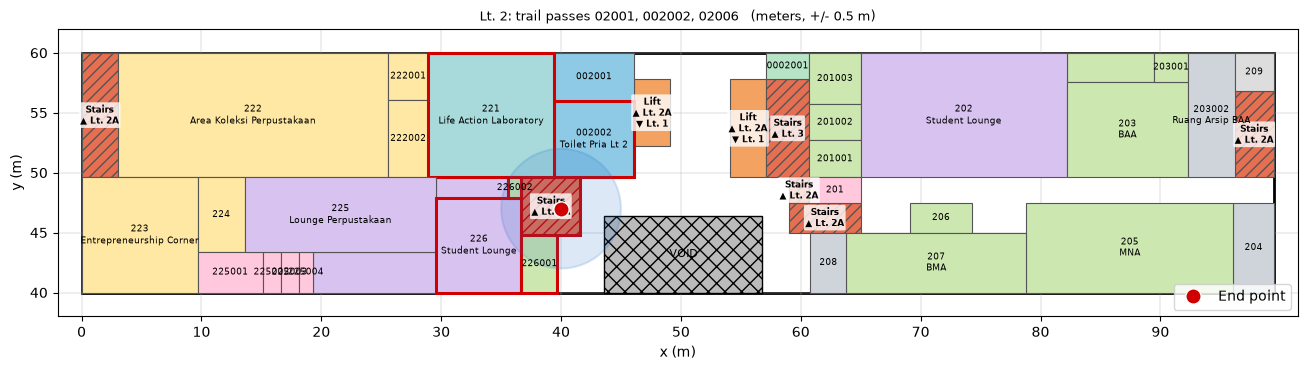

Lt. 2: walked 18 m, rooms along the trail (3):
   02001 Lift Barat Lt 2 > 002002 Toilet Pria Lt 2 > 02006 Tangga Tengah Barat Lt 2



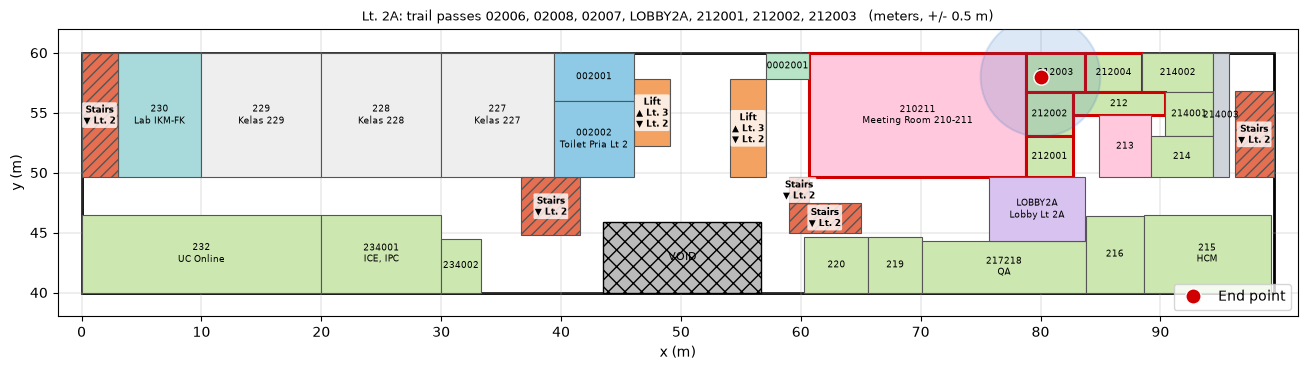

Lt. 2A: walked 51 m, rooms along the trail (7):
   02006 Tangga Tengah Barat Lt 2 > 02008 Tangga Tengah Timur Pendek Lt 2 > 02007 Tangga Tengah Timur Lt 2 > LOBBY2A Lobby Lt 2A > 212001 Ruang Vice 1 > 212002 Ruang Vice 2 > 212003 Ruang Rector



In [5]:
for floor in nav.floors:
    points = [(r["x"], r["y"]) for r in log if r["floor"] == floor]
    # the last stretch of this floor: where the visitor ended up on it
    end = points[-1]
    data = nav.floors[floor]
    fig, ax = plt.subplots(figsize=(16, 4.8))
    patches = draw_floor(ax, floor, data["rooms"], data["walkable"])

    buffer = buffer_around(*end, RADIUS)                        # Buffer
    for room in spatial_join(data["rooms"], buffer):            # Spatial Join 1
        patches[room["room_id"]].set_edgecolor("#d00000")
        patches[room["room_id"]].set_linewidth(2.2)
    add_polygon(ax, buffer, facecolor="#1565c0", alpha=0.15, edgecolor="#1565c0", linewidth=1.5, zorder=3)

    route = LineString(points)                                  # LineString layer (used by the join, not drawn)
    ax.plot(*end, "o", color="#d00000", markersize=11, markeredgecolor="white", zorder=7, label="End point")
    passed = rooms_along_route(data["rooms"], route)            # Spatial Join 2
    ax.set_title(f"Lt. {floor}: trail passes {', '.join(r['room_id'] for r in passed)}   (meters, +/- 0.5 m)", fontsize=9)
    ax.legend(loc="lower right")
    plt.show()
    print(f"Lt. {floor}: walked {route.length:.0f} m, rooms along the trail ({len(passed)}):")
    print("   " + " > ".join(f"{r['room_id']} {r['name'].split(' (')[0]}" for r in passed))
    print()

In [6]:
total = sum(abs(a["x"] - b["x"]) + abs(a["y"] - b["y"]) for a, b in zip(log, log[1:]) if a["floor"] == b["floor"])
print(f"Total distance walked: {total:.0f} m (plus one stair, Lt. 2 to Lt. 2A)")
print("Arrived in:", log[-1]["in"], "on Lt.", log[-1]["floor"])

Total distance walked: 69 m (plus one stair, Lt. 2 to Lt. 2A)
Arrived in: Ruang Rector (212C) on Lt. 2A


## 4. Try it yourself: WASD buttons
A notebook cannot read real key presses, so the buttons below stand in for W / A / S / D.
**E** takes the stair or lift up, **Q** takes it down (stand inside a stair or lift first). Run the cell, then click.
For real keyboard keys use the Streamlit app (`streamlit run streamlit_app.py`).

In [7]:
import ipywidgets as widgets
from IPython.display import clear_output, display

live = Navigator("2", radius=RADIUS)
out = widgets.Output()

def show():
    with out:
        clear_output(wait=True)
        data = live.floors[live.floor]
        fig, ax = plt.subplots(figsize=(14, 4.2))
        patches = draw_floor(ax, live.floor, data["rooms"], data["walkable"])
        near = live.nearby()                                       # Buffer + Spatial Join
        for room, _ in near:
            patches[room["room_id"]].set_edgecolor("#d00000")
            patches[room["room_id"]].set_linewidth(2.2)
        add_polygon(ax, live.buffer(), facecolor="#1565c0", alpha=0.15, edgecolor="#1565c0", zorder=3)
        ax.plot(live.x, live.y, "o", color="#d00000", markersize=11, markeredgecolor="white", zorder=7)
        ax.set_title(f"Lt. {live.floor}  at ({live.x:g}, {live.y:g}) m  (meters, +/- 0.5 m)")
        plt.show()
        here = live.here()
        print("You are in:", here["name"] if here else "corridor / lobby")
        if live.link_hint():
            print(live.link_hint())
        print("Rooms in the buffer:", ", ".join(r["room_id"] for r, _ in near))

def on_click(button):
    key = button.description.lower()
    message = (live.change_floor(up=key == "e") if key in "eq"
               else live.move(*{"w": (0, 1), "a": (-1, 0), "s": (0, -1), "d": (1, 0)}[key]))
    show()
    if message:
        with out:
            print(message)

buttons = {k: widgets.Button(description=k.upper(), layout=widgets.Layout(width="60px")) for k in "wasdeq"}
for b in buttons.values():
    b.on_click(on_click)
pad = widgets.VBox([widgets.HBox([buttons["q"], buttons["w"], buttons["e"]]),
                    widgets.HBox([buttons["a"], buttons["s"], buttons["d"]])])
display(pad, out)
show()

Output()

## 5. Notes and limits
- Sizes are estimates measured from pictures (+/- 0.5 m). Walls and doors are not modeled: every room is walkable for now, and only the void and the outside block movement.
- Stair and lift links between Lt. 2 and 2A are team assumptions. The end stairs are unconfirmed.
- Only Lt. 2 and Lt. 2A are mapped so far. Other floors are added as files in `floors/` and `csv/`.
- Route search (AI course) is in a separate part of the project.